# Qiskit Block Encoding for the Burgers Equation

This notebook demonstrates the quantum implementation of the
operators appearing in the one-dimensional Burgers equation.

The classical Burgers solver provides the discretized field and
differential operators. The field is amplitude encoded into a
quantum state, while the nonlinear field-dependent operator is
represented using a diagonal block encoding.

The objective is to verify the block encoding numerically before
constructing the complete hybrid quantum-classical time-stepping
algorithm.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import sqrtm

from qiskit import QuantumCircuit
from qiskit.circuit.library import UnitaryGate
from qiskit.quantum_info import Statevector

In [2]:
data = np.load("../results/data/burgers_classical_data.npz")

x = data["x"]
times = data["times"]
solutions = data["solutions"]

print("x shape:", x.shape)
print("times:", times)
print("solutions shape:", solutions.shape)

u = solutions[-1]

print("Time:", times[-1])
print("u =", u)

x shape: (8,)
times: [0.  0.1 0.2 0.3 0.4 0.5]
solutions shape: (6, 8)
Time: 0.5
u = [0.00000000e+00 1.57767192e-01 3.10550179e-01 4.50815488e-01
 5.62318168e-01 6.00812330e-01 4.50918434e-01 1.22464680e-16]


In [3]:
u_norm = np.linalg.norm(u)

print("||u|| =", u_norm)

||u|| = 1.0977573124911373


In [4]:
u_state = u / u_norm

print("Normalized state:")
print(u_state)

print("Norm =", np.linalg.norm(u_state))

Normalized state:
[0.00000000e+00 1.43717733e-01 2.82895113e-01 4.10669538e-01
 5.12242698e-01 5.47308884e-01 4.10763316e-01 1.11558974e-16]
Norm = 1.0


In [5]:
psi = Statevector(u_state)

print(psi)

Statevector([0.00000000e+00+0.j, 1.43717733e-01+0.j, 2.82895113e-01+0.j,
             4.10669538e-01+0.j, 5.12242698e-01+0.j, 5.47308884e-01+0.j,
             4.10763316e-01+0.j, 1.11558974e-16+0.j],
            dims=(2, 2, 2))


In [6]:
psi_array = np.asarray(psi.data)

print("Maximum difference:")
print(np.max(np.abs(psi_array - u_state)))

Maximum difference:
0.0


In [7]:
N = len(u)
dx = x[1] - x[0]

Dx = np.zeros((N, N))

for i in range(1, N-1):
    Dx[i, i-1] = -1 / (2*dx)
    Dx[i, i+1] = 1 / (2*dx)

In [8]:
Dxx = np.zeros((N, N))

for i in range(1, N-1):
    Dxx[i, i-1] = 1 / dx**2
    Dxx[i, i] = -2 / dx**2
    Dxx[i, i+1] = 1 / dx**2

In [9]:
Du = np.diag(u)

print(Du)

[[0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
  0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 1.57767192e-01 0.00000000e+00 0.00000000e+00
  0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00 3.10550179e-01 0.00000000e+00
  0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00 0.00000000e+00 4.50815488e-01
  0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
  5.62318168e-01 0.00000000e+00 0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
  0.00000000e+00 6.00812330e-01 0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
  0.00000000e+00 0.00000000e+00 4.50918434e-01 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
  0.00000000e+00 0.00000000e+00 0.00000000e+00 1.22464680e-16]]

In [10]:
ux = Dx @ u

nonlinear_direct = u * ux
nonlinear_matrix = Du @ Dx @ u

error = (
    np.linalg.norm(
        nonlinear_direct - nonlinear_matrix
    )
    /
    np.linalg.norm(nonlinear_direct)
)

print("Nonlinear operator error:", error)

Nonlinear operator error: 1.522253260053223e-16


apply D_u

In [11]:
beta_u = np.max(np.abs(u))

print("beta_u =", beta_u)

beta_u = 0.6008123299171806


In [12]:
A_u = Du / beta_u

In [13]:
print(
    "Maximum diagonal magnitude:",
    np.max(np.abs(np.diag(A_u)))
)

Maximum diagonal magnitude: 1.0


In [14]:
I = np.eye(N)

upper_right = np.linalg.matrix_power(
    I - A_u @ A_u.conj().T,
    1
)

In [15]:
upper_right = sqrtm(
    I - A_u @ A_u.conj().T
)

lower_left = sqrtm(
    I - A_u.conj().T @ A_u
)

C:\Users\nasin\AppData\Local\Temp\ipykernel_29824\4102132010.py:1: LinAlgWarning: Matrix is singular. The result might be inaccurate or the array might not have a square root.
  upper_right = sqrtm(
C:\Users\nasin\AppData\Local\Temp\ipykernel_29824\4102132010.py:5: LinAlgWarning: Matrix is singular. The result might be inaccurate or the array might not have a square root.
  lower_left = sqrtm(


In [16]:
U_u = np.block([
    [A_u, upper_right],
    [lower_left, -A_u.conj().T]
])

In [17]:
unitarity_error = np.linalg.norm(
    U_u.conj().T @ U_u - np.eye(2*N)
)

print("Unitarity error:", unitarity_error)

Unitarity error: 1.1856791024106567e-16


In [18]:
block_error = np.linalg.norm(
    U_u[:N, :N] - A_u
)

print("Block encoding error:", block_error)

Block encoding error: 0.0


In [19]:
U_gate = UnitaryGate(
    U_u,
    label="U_u"
)

In [20]:
qc = QuantumCircuit(4)

In [21]:
qc.initialize(
    u_state,
    [1, 2, 3]
)

In [22]:
qc.append(
    U_gate,
    [0, 1, 2, 3]
)

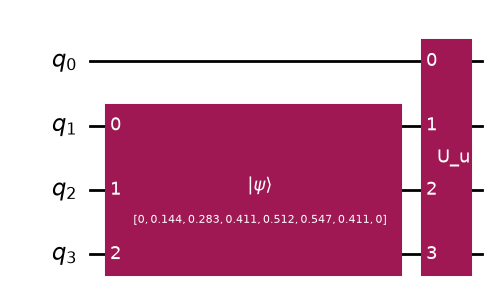

In [23]:
qc.draw("mpl")

In [24]:
final_state = Statevector.from_instruction(qc)

final_array = np.asarray(final_state.data)

print(final_array)

[ 0.5122427 +0.j  0.        +0.j  0.54281218+0.j  0.        +0.j
  0.4094353 +0.j  0.        +0.j  0.30821349+0.j  0.        +0.j
  0.        +0.j  0.        +0.j -0.15986475+0.j  0.        +0.j
 -0.28481376+0.j  0.        +0.j  0.27139255+0.j  0.        +0.j]


In [25]:
successful_branch = final_array[:N]

print("Successful branch:")
print(successful_branch)

Successful branch:
[0.5122427 +0.j 0.        +0.j 0.54281218+0.j 0.        +0.j
 0.4094353 +0.j 0.        +0.j 0.30821349+0.j 0.        +0.j]


In [26]:
expected_branch = (
    A_u @ u_state
)

In [27]:
quantum_error = np.linalg.norm(
    successful_branch - expected_branch
)

print(
    "Quantum block encoding error:",
    quantum_error
)

Quantum block encoding error: 0.9058126558222415


In [28]:
success_probability = np.linalg.norm(
    successful_branch
)**2

print(
    "Success probability:",
    success_probability
)

Success probability: 0.819670466788624


In [29]:
success_probability_classical = (
    np.linalg.norm(
        A_u @ u_state
    )**2
)

print(
    "Classical prediction:",
    success_probability_classical
)

Classical prediction: 0.7421904090697324


In [30]:
print(
    "Difference:",
    abs(
        success_probability
        -
        success_probability_classical
    )
)

Difference: 0.07748005771889155


In [31]:
beta_x = np.linalg.norm(Dx, 2)

print("beta_x =", beta_x)

beta_x = 6.467156727579007


In [32]:
A_x = Dx / beta_x

In [33]:
print(
    "||A_x|| =",
    np.linalg.norm(A_x, 2)
)

||A_x|| = 1.0


In [34]:
def block_encode(A):

    n = A.shape[0]
    I = np.eye(n)

    top_right = sqrtm(
        I - A @ A.conj().T
    )

    bottom_left = sqrtm(
        I - A.conj().T @ A
    )

    U = np.block([
        [A, top_right],
        [bottom_left, -A.conj().T]
    ])

    return U

In [35]:
U_x = block_encode(A_x)

C:\Users\nasin\AppData\Local\Temp\ipykernel_29824\562549956.py:6: LinAlgWarning: Matrix is singular. The result might be inaccurate or the array might not have a square root.
  top_right = sqrtm(


In [36]:
print(
    "Dx block unitarity error:",
    np.linalg.norm(
        U_x.conj().T @ U_x
        -
        np.eye(2*N)
    )
)

Dx block unitarity error: 1.490116119385046e-08


In [37]:
nu = 0.1
dt = 0.001

I = np.eye(N)

L_operator = (
    I
    +
    nu * dt * Dxx
)

In [38]:
beta_L = np.linalg.norm(
    L_operator,
    2
)

print("beta_L =", beta_L)

beta_L = 1.0008645351256706


In [39]:
A_L = L_operator / beta_L

In [40]:
U_L = block_encode(A_L)

In [41]:
print(
    "Linear block unitarity error:",
    np.linalg.norm(
        U_L.conj().T @ U_L
        -
        np.eye(2*N)
    )
)

Linear block unitarity error: 5.1353189713729675e-08
